# Milestone 4: Advanced Models, Fairness Audit and Bias Mitigation

**Trans-Boundary Smog Prediction: Crop Fires and Climate Traps across Punjab (Pakistan and India)**
Munir Tariq (10067), Ismail Nooruddin (09958), Bilal Ayub (09716)

- **Goal:** predict whether a city has a smog spike tomorrow (`target_spike_h1`), and check whether the alert treats places fairly.
- **Inputs:** `Dataset/clean/master_daily.parquet`, `Dataset/clean/role2_params.json`, `Dataset/clean/m3_params.json`, the Milestone 3 models in `models/`, the Milestone 3 validation metrics `docs/tables/m3_metrics_validation.csv`, and the census table `Dataset/external/city_population.csv`.
- **Code:** `src/modeling.py` (data, CV, pipelines, search), `src/evaluate.py` (metrics, bootstrap, costs) and `src/fairness.py` (groups, fairness metrics, mitigation).
- **Run:** Kernel > Restart and Run All, from the repository root (about 35–40 minutes on 8 cores). Seeds are fixed.
- **Rules:** we fit, tune, weight and set thresholds on training rows only (2022-08-04 to 2023-08-31).
- Validation (2023-09-04 to 2023-12-31) only reports results. 2024 stays sealed.

| Section | Content | Rubric part |
|---|---|---|
| M4.1 | Data, split and the sensitive groups | A, B |
| M4.2 | Random forest and gradient boosting: random search on the purged folds | A |
| M4.3 | Comparison with the Milestone 3 baselines; calibration; cost | A |
| M4.4 | Fire ablation and drivers of the ensemble models | A, C |
| M4.5 | Hypotheses H1 (cone vs radius), H3 (fire × stagnation), H4 (cross-border) | C |
| M4.6 | Fairness audit by country, city-size tier and city | B |
| M4.7 | Bias mitigation: reweighing and group thresholds | Mitigation |
| M4.8 | Fairness–accuracy Pareto frontier | B, Mitigation |
| M4.9 | Threshold curves and asymmetric costs by group | Mitigation |
| M4.10 | Saved models and parameters | Code |
| Summary | Findings, FATEN notes and governance | C |

In [1]:
# ------------------------------------------------------------
# Setup: imports, paths and settings
# ------------------------------------------------------------
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path.cwd()                          # run from the repository root
sys.path.append(str(ROOT))

import joblib
from sklearn.base import clone
from src import config as C                # shared rules: cities, dates, folders
from src import modeling as MD             # data access, CV, pipelines, search, thresholds
from src import evaluate as EV             # metrics, bootstrap, cost curve
from src import fairness as FA             # groups, fairness metrics, mitigation
from src import plotting as P              # one figure style for every figure
from src.evaluate import save_table

P.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
T0 = time.time()

H = 1
TARGET = f"target_spike_h{H}"
COST_FN, COST_FP = EV.COST_FN, EV.COST_FP  # 5:1, as in Milestone 3
N_BOOT = 1000
EPS_HEADLINE = 0.05                        # fairness band for the headline mitigations (fixed before results)

role2 = json.loads((C.CLEAN_DIR / "role2_params.json").read_text())
m3 = json.loads((C.CLEAN_DIR / "m3_params.json").read_text())
assert role2["fire_setting"]["tag"] == "up45_r300"

SETS = list(MD.FEATURE_SETS)                                   # full, weather_only, no_fire
SET_LABEL = {"full": "full", "weather_only": "weather-only", "no_fire": "no-fire"}
FAMS = ["lr", "dt", "rf", "hgb"]
FAM_LABEL = {"lr": "LR", "dt": "DT", "rf": "RF", "hgb": "HGB"}
MODELS = ["majority", "persistence"] + [f"{f}_{s}" for f in FAMS for s in SETS]
LABEL = {"majority": "Majority class", "persistence": "Persistence",
         **{f"{f}_{s}": f"{FAM_LABEL[f]} {SET_LABEL[s]}" for f in FAMS for s in SETS}}
FAM_COLOR = {"lr": P.CAT_COLORS[0], "dt": P.CAT_COLORS[1], "rf": P.CAT_COLORS[2], "hgb": P.CAT_COLORS[3]}
COLOR = {"majority": P.GREY, "persistence": "#000000", **{f"{f}_{s}": FAM_COLOR[f] for f in FAMS for s in SETS}}

---
## M4.1 Data, split and sensitive groups

- Same rows, split and drops as Milestone 3 (`MD.load_model_frame`).
- **Sensitive attribute = geography** (agreed with the instructor):
  - **country:** Pakistan (7 cities) vs India (4 cities);
  - **city-size tier**, a socio-economic proxy from census population (city including cantonments): Tier 1 metro ≥ 3 M, Tier 2 large 1–3 M, Tier 3 small < 1 M;
  - **city** (11), reported descriptively because each city has few spikes.
- The tier rule was fixed before any fairness result (DECISIONS.md, row P1).
- **Reference ("privileged") groups:** Pakistan for country, Tier 1 metros for tier, Lahore for city. Metros have the most monitoring, media attention and administrative capacity.

In [2]:
df, drop_log = MD.load_model_frame(H)
train = FA.add_groups(df[df["split"] == "train"].reset_index(drop=True))
val = FA.add_groups(df[df["split"] == "validation"].reset_index(drop=True))
y_tr, y_va = train[TARGET].to_numpy(), val[TARGET].to_numpy()
assert train["date"].max() <= pd.Timestamp(C.TRAIN_END) < pd.Timestamp(C.VALID_START) <= val["date"].min()
assert df["date"].max() < MD.SEALED_FROM
assert (len(train), int(y_tr.sum()), len(val), int(y_va.sum())) == (4246, 204, 1298, 89), "rows differ from Milestone 3"


def assert_train_only(frame):
    # Called before every fit: only training-period rows may reach a model
    assert frame["date"].max() <= pd.Timestamp(C.TRAIN_END), "a validation row reached a fit"
    assert (frame["split"] == "train").all()


tiers = FA.load_city_tiers()
PRIV = {"country_name": "Pakistan", "tier": FA.TIER_LABEL[1], "city": "Lahore"}
GROUPINGS = {"country_name": "country", "tier": "city-size tier", "city": "city"}

rows = []
for _, r in tiers.iterrows():
    tr_c, va_c = train[train.city == r.city], val[val.city == r.city]
    rows.append({"city": r.city, "country": r.country, "census_year": r.census_year, "population": r.population,
                 "tier": FA.TIER_LABEL[r.tier], "spike_threshold": tr_c["spike_threshold"].iloc[0],
                 "train_days": len(tr_c), "train_spikes": int(tr_c[TARGET].sum()),
                 "train_rate": tr_c[TARGET].mean(), "val_days": len(va_c), "val_spikes": int(va_c[TARGET].sum()),
                 "val_rate": va_c[TARGET].mean()})
groups_tab = pd.DataFrame(rows).sort_values(["tier", "population"], ascending=[True, False])
_ = save_table(groups_tab, "m4_groups", index=False)
print(groups_tab.round(4).to_string(index=False))

summary_rows = []
for col in ["country_name", "tier"]:
    for g in sorted(train[col].unique()):
        a, b = train[train[col] == g], val[val[col] == g]
        summary_rows.append({"grouping": GROUPINGS[col], "group": g, "cities": a.city.nunique(),
                             "train_days": len(a), "train_spikes": int(a[TARGET].sum()), "train_rate": a[TARGET].mean(),
                             "val_days": len(b), "val_spikes": int(b[TARGET].sum()), "val_rate": b[TARGET].mean()})
group_summary = pd.DataFrame(summary_rows)
_ = save_table(group_summary, "m4_group_summary", index=False)
print()
print(group_summary.round(4).to_string(index=False))

          city country  census_year  population                 tier  spike_threshold  train_days  train_spikes  train_rate  val_days  val_spikes  val_rate
        Lahore      PK         2023    13004135 Tier 1 metro (≥ 3 M)           2.1771         386            17      0.0440       118           1    0.0085
    Faisalabad      PK         2023     3691999 Tier 1 metro (≥ 3 M)           1.5878         386            17      0.0440       118          11    0.0932
    Rawalpindi      PK         2023     3357612 Tier 1 metro (≥ 3 M)           0.6543         386            23      0.0596       118           0    0.0000
        Multan      PK         2023     2215381 Tier 2 large (1–3 M)           1.2505         386            18      0.0466       118          10    0.0847
      Ludhiana      IN         2011     1618879 Tier 2 large (1–3 M)           1.1731         386            18      0.0466       118          10    0.0847
      Amritsar      IN         2011     1169637 Tier 2 large (1–

**What we found (M4.1)**

- **Training spike rates are nearly equal across groups** (4.6–4.9% in every tier and country). Each city's spike threshold is its own training P90, so this holds by design.
- **Validation base rates differ.** Tier 3 small cities had 11.0% spike days, Tier 2 5.3% and Tier 1 metros 3.4%. India had 8.5% and Pakistan 5.9%.
- Rahim Yar Khan alone had 22 validation spikes. Rawalpindi and Islamabad had none.
- **Consequence:** an alert that follows the spikes must alert more often in small cities on validation. Equal alert rates (demographic parity) are therefore not a fair target here.

---
## M4.2 Advanced models: random forest and gradient boosting

**Why these two**
- **Random forest (RF):** averages many decorrelated trees. It captures interactions (for example fire × stagnation) and tolerates correlated lags.
- **Histogram gradient boosting (HGB):** scikit-learn's implementation of the LightGBM algorithm. It builds trees in sequence on the errors of the previous ones and is the standard strong learner for tabular data.
- Both run on the same feature sets (full, weather-only, no-fire) and the **same 25 purged, week-grouped, stratified folds** as the baselines.

**Search (random search, 60 draws per model and feature set, scored by PR-AUC)**
- RF: trees {300, 500}, depth {3, 4, 5, 6, 8, 10, 12, none}, minimum leaf {5, 10, 25, 50, 100}, features per split {√p, 0.3, 0.5, 1.0}, class weight {none, balanced, balanced per bootstrap}.
- HGB: learning rate 0.01–0.3 (log-uniform), rounds 100–600, leaves {7, 15, 31, 63}, depth {none, 3, 5, 8}, minimum leaf 10–100, L2 penalty 0.001–10 (log-uniform), class weight {none, balanced}.
- **HGB early stopping is off.** It would hold out a random 10% of the fit rows, so neighbouring days of one week would sit on both sides. The number of rounds is tuned on the purged folds instead.
- The log transform of fire counts sits inside the pipeline. Trees need no scaling.

**Baselines from Milestone 3.** We load the fitted LR and DT pipelines from `models/` and recompute their out-of-fold predictions on the same folds. The recomputed thresholds must match `m3_params.json`.

In [3]:
splits = MD.purged_sgkf_splits(train, y_tr, n_splits=5, seeds=range(5), horizon=H)
assert len(splits) == 25
X_tr = {s: train[MD.FEATURE_SETS[s]] for s in SETS}
X_va = {s: val[MD.FEATURE_SETS[s]] for s in SETS}
assert_train_only(train)

searches, tuning = {}, {"rf": [], "hgb": []}
for fam, make, dist in [("rf", MD.make_rf, MD.RF_DIST), ("hgb", MD.make_hgb, MD.HGB_DIST)]:
    for s in SETS:
        t = time.time()
        rs = MD.tune_random(make(MD.FEATURE_SETS[s]), dist, X_tr[s], y_tr, splits, n_iter=MD.N_ITER, seed=42)
        searches[f"{fam}_{s}"] = rs
        res = pd.DataFrame(rs.cv_results_["params"])
        res.columns = [c.replace("model__", "") for c in res.columns]
        res = res.astype(object).where(res.notna(), "none")
        res = res.assign(feature_set=s, cv_pr_auc_mean=rs.cv_results_["mean_test_score"],
                         cv_pr_auc_sd=rs.cv_results_["std_test_score"], rank=rs.cv_results_["rank_test_score"])
        tuning[fam].append(res)
        print(f"{LABEL[f'{fam}_{s}']:<18} best CV PR-AUC {rs.best_score_:.4f}  "
              f"{ {k.replace('model__', ''): (round(float(v), 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()} }"
              f"  ({time.time() - t:.0f} s)")
tuning_rf, tuning_hgb = pd.concat(tuning["rf"]), pd.concat(tuning["hgb"])
_ = save_table(tuning_rf, "m4_tuning_rf", index=False)
_ = save_table(tuning_hgb, "m4_tuning_hgb", index=False)

RF full            best CV PR-AUC 0.5904  {'n_estimators': 500, 'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': 4, 'class_weight': None}  (871 s)


RF weather-only    best CV PR-AUC 0.4105  {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 6, 'class_weight': None}  (675 s)


RF no-fire         best CV PR-AUC 0.5913  {'n_estimators': 500, 'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': 4, 'class_weight': None}  (755 s)


HGB full           best CV PR-AUC 0.5647  {'class_weight': 'balanced', 'l2_regularization': 0.0572, 'learning_rate': 0.0199, 'max_depth': 8, 'max_iter': 330, 'max_leaf_nodes': 7, 'min_samples_leaf': 61}  (470 s)


HGB weather-only   best CV PR-AUC 0.4067  {'class_weight': None, 'l2_regularization': 0.0049, 'learning_rate': 0.0378, 'max_depth': 3, 'max_iter': 459, 'max_leaf_nodes': 63, 'min_samples_leaf': 11}  (359 s)


HGB no-fire        best CV PR-AUC 0.5796  {'class_weight': 'balanced', 'l2_regularization': 0.111, 'learning_rate': 0.0551, 'max_depth': None, 'max_iter': 119, 'max_leaf_nodes': 7, 'min_samples_leaf': 17}  (407 s)


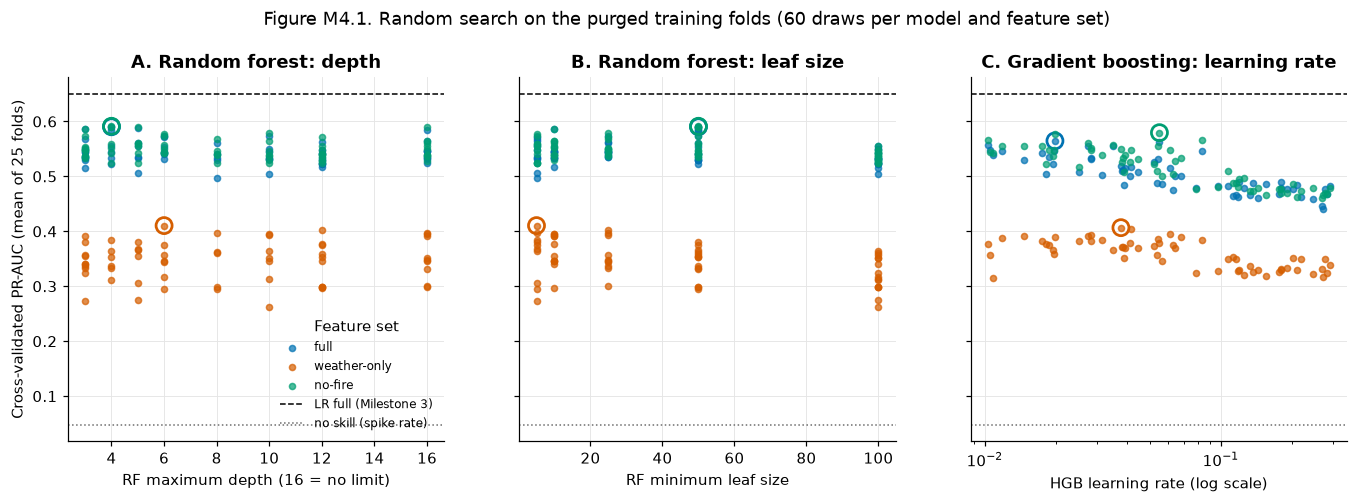

In [4]:
# Figure M4.1: what the search found (every draw = one point; best draw circled)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
SET_COLOR = {"full": P.CAT_COLORS[0], "weather_only": P.CAT_COLORS[1], "no_fire": P.CAT_COLORS[2]}
depth_num = lambda v: 16 if v == "none" else v
panels = [(axes[0], tuning_rf, "max_depth", "RF maximum depth (16 = no limit)", "A. Random forest: depth", depth_num),
          (axes[1], tuning_rf, "min_samples_leaf", "RF minimum leaf size", "B. Random forest: leaf size", None),
          (axes[2], tuning_hgb, "learning_rate", "HGB learning rate (log scale)", "C. Gradient boosting: learning rate", None)]
for ax, tab, x, xlabel, title, conv in panels:
    for s in SETS:
        d = tab[tab.feature_set == s]
        xv = d[x].map(conv) if conv else d[x].astype(float)
        ax.scatter(xv, d["cv_pr_auc_mean"], s=16, color=SET_COLOR[s], alpha=0.7, label=SET_LABEL[s])
        b = d.loc[d["cv_pr_auc_mean"].idxmax()]
        ax.scatter(conv(b[x]) if conv else float(b[x]), b["cv_pr_auc_mean"], s=110, facecolor="none",
                   edgecolor=SET_COLOR[s], lw=1.8)
    ax.axhline(m3["models"]["lr_full"]["cv_pr_auc"], color="#000000", ls="--", lw=1, label="LR full (Milestone 3)")
    ax.axhline(y_tr.mean(), color=P.GREY, ls=":", lw=1, label="no skill (spike rate)")
    ax.set_xlabel(xlabel); ax.set_title(title)
axes[2].set_xscale("log")
axes[0].set_ylabel("Cross-validated PR-AUC (mean of 25 folds)")
axes[0].legend(title="Feature set", loc="lower right", fontsize=8)
fig.suptitle("Figure M4.1. Random search on the purged training folds (60 draws per model and feature set)", y=1.02)
P.save(fig, "fig_m04_1_tuning")
plt.show()

In [5]:
# Out-of-fold predictions and 5:1 thresholds for every model (Milestone 3 models reloaded, not retuned)
fitted, oof, cv_folds, thresholds, cv_score = {}, {}, {}, {}, {}
assert_train_only(train)
fitted["majority"] = joblib.load("models/majority.joblib")
oof["majority"], cv_folds["majority"] = MD.oof_predict(MD.make_majority(), X_tr["full"], y_tr, splits)
for f in ["lr", "dt"]:
    for s in SETS:
        m = f"{f}_{s}"
        fitted[m] = joblib.load(f"models/{m}.joblib")
        oof[m], cv_folds[m] = MD.oof_predict(fitted[m], X_tr[s], y_tr, splits)
        cv_score[m] = m3["models"][m]["cv_pr_auc"]
for m, rs in searches.items():
    fitted[m] = rs.best_estimator_
    oof[m], cv_folds[m] = MD.oof_predict(rs.best_estimator_, X_tr[m.split("_", 1)[1]], y_tr, splits)
    cv_score[m] = float(rs.best_score_)
for m in oof:
    thresholds[m], _ = MD.choose_threshold(y_tr, oof[m], COST_FN, COST_FP)
for m in [f"{f}_{s}" for f in ["lr", "dt"] for s in SETS]:          # reproducibility check against Milestone 3
    assert abs(thresholds[m] - m3["models"][m]["threshold"]) < 1e-9, f"{m}: threshold differs from Milestone 3"

pers_score_tr, pers_yhat_tr = MD.persistence(train)
pers_score_va, pers_yhat_va = MD.persistence(val)

# Final-model rule (fixed before validation): highest CV PR-AUC among the full-feature models;
# a model within 0.005 of the best counts as tied, and the simplest tied model wins (LR < DT < RF < HGB).
cands = ["lr_full", "dt_full", "rf_full", "hgb_full"]
best = max(cv_score[m] for m in cands)
FINAL = next(m for m in cands if cv_score[m] >= best - 0.005)
BEST_ADV = max(["rf_full", "hgb_full"], key=lambda m: cv_score[m])
AUDIT = ["persistence", "lr_full", BEST_ADV] + ([FINAL] if FINAL not in ("lr_full", BEST_ADV) else [])
MITIGATE = list(dict.fromkeys([FINAL, BEST_ADV]))
print(pd.Series({LABEL[m]: cv_score[m] for m in cands}, name="CV PR-AUC").round(4).to_string())
print(f"\nFinal model: {LABEL[FINAL]}; best ensemble: {LABEL[BEST_ADV]}")
print("Thresholds (OOF, 5:1):", {LABEL[m]: round(thresholds[m], 4) for m in thresholds})

LR full     0.6508
DT full     0.5190
RF full     0.5904
HGB full    0.5647

Final model: LR full; best ensemble: RF full
Thresholds (OOF, 5:1): {'Majority class': inf, 'LR full': 0.128, 'LR weather-only': 0.1009, 'LR no-fire': 0.128, 'DT full': 0.1988, 'DT weather-only': 0.1173, 'DT no-fire': 0.1988, 'RF full': 0.1747, 'RF weather-only': 0.115, 'RF no-fire': 0.143, 'HGB full': 0.5775, 'HGB weather-only': 0.0897, 'HGB no-fire': 0.5782}


**What we found (M4.2)**

- **RF full:** 500 trees, depth 4, minimum leaf 50, half the columns per split, no class weight. CV PR-AUC 0.590.
- **HGB full:** learning rate 0.020, 330 rounds, 7 leaves, depth 8, minimum leaf 61, L2 0.057, balanced class weight. CV PR-AUC 0.565.
- Both searches chose shallow, heavily regularised trees.
- **Neither ensemble reaches LR full in CV** (0.651). Under the rule fixed in advance, **LR full stays the final model**. RF full is the best ensemble.
- The weather-only sets reach only 0.41 for both ensembles. AQ history carries the signal.
- HGB's 5:1 threshold is 0.578, against 0.175 for RF. Balanced class weights push HGB's probabilities upwards.

---
## M4.3 Comparison with the Milestone 3 baselines

- **Metrics:** accuracy, precision, recall, specificity, F1, ROC-AUC, PR-AUC, Brier score and cost per 1,000 city-days at each model's 5:1 threshold.
- **Cross-validation:** mean ± SD over the 25 folds. **Validation:** 95% CIs from a block bootstrap over whole weeks.
- **Paired differences:** each ensemble against LR full, DT full and persistence, on the same resampled weeks and in each CV fold.
- **Calibration:** reliability curves on validation. Alert thresholds come from OOF predictions, so calibration does not change the alerts. It matters when officials read a probability at face value.

In [6]:
METRICS = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "brier", "cost_per_1000"]
cv_rows = {"persistence": EV.cv_metrics(y_tr, [(t, pers_score_tr[t]) for _, t in splits], yhat=pers_yhat_tr)}
for m in oof:
    cv_rows[m] = EV.cv_metrics(y_tr, cv_folds[m], threshold=thresholds[m])
metrics_cv = pd.DataFrame(cv_rows).T.loc[MODELS]
metrics_cv.index = [LABEL[m] for m in MODELS]
metrics_cv.index.name = "model"
_ = save_table(metrics_cv[[f"{k}_{s}" for k in METRICS for s in ("mean", "sd")]], "m4_metrics_cv")

score_va, yhat_va = {"persistence": pers_score_va}, {"persistence": pers_yhat_va}
for m in oof:
    score_va[m] = fitted[m].predict_proba(X_va["full" if m == "majority" else m.split("_", 1)[1]])[:, 1]
    yhat_va[m] = (score_va[m] >= thresholds[m]).astype(int)
vframe = val[["city", "country", "country_name", "tier", "date", "persist_spike", TARGET, "target_index_h1"]].copy()
for m in MODELS:
    vframe[f"s_{m}"], vframe[f"p_{m}"] = score_va[m], yhat_va[m]


def all_model_metrics(d):
    out = {}
    for m in MODELS:
        r = EV.binary_metrics(d[TARGET], d[f"s_{m}"], yhat=d[f"p_{m}"])
        out.update({f"{m}|{k}": r[k] for k in METRICS})
    return out


boot = EV.block_bootstrap(vframe, all_model_metrics, n=N_BOOT, seed=42)
boot.index = pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in boot.index], names=["model", "metric"])
counts = pd.DataFrame({m: EV.binary_metrics(y_va, score_va[m], yhat=yhat_va[m]) for m in MODELS}).T
metrics_val = boot.reset_index()
metrics_val["model"] = metrics_val["model"].map(LABEL)
_ = save_table(metrics_val, "m4_metrics_validation", index=False)
counts.index = [LABEL[m] for m in MODELS]
_ = save_table(counts[["tp", "fp", "tn", "fn", "n"]].astype(int), "m4_validation_counts")

# The reloaded Milestone 3 models must reproduce the Milestone 3 validation numbers
m3_val = pd.read_csv("docs/tables/m3_metrics_validation.csv")
for m in ["lr_full", "dt_full", "persistence"]:
    old = m3_val[(m3_val.model == LABEL[m]) & (m3_val.metric == "pr_auc")]["estimate"].iloc[0]
    assert abs(old - boot.loc[(m, "pr_auc"), "estimate"]) < 1e-4, f"{m} does not reproduce Milestone 3"

fmt = boot.apply(lambda r: f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1).unstack("metric")
fmt = fmt.loc[MODELS, METRICS]; fmt.index = [LABEL[m] for m in MODELS]
print("Cross-validated metrics (mean of 25 folds)")
print(metrics_cv[[f"{k}_mean" for k in METRICS]].round(3).to_string())
print(f"\nValidation metrics, 95% block-bootstrap CI ({boot['n_weeks'].iloc[0]} weeks resampled)")
print(fmt.to_string())
print("\nValidation confusion counts"); print(counts[["tp", "fp", "tn", "fn"]].astype(int).to_string())

Cross-validated metrics (mean of 25 folds)
                  accuracy_mean  precision_mean  recall_mean  specificity_mean  f1_mean  roc_auc_mean  pr_auc_mean  brier_mean  cost_per_1000_mean
model                                                                                                                                             
Majority class            0.952             NaN        0.000             1.000    0.000           NaN          NaN       0.048             240.563
Persistence               0.961           0.579        0.579             0.979    0.575         0.969        0.636         NaN             113.973
LR full                   0.927           0.396        0.924             0.927    0.546         0.972        0.651       0.028              86.678
LR weather-only           0.903           0.402        0.669             0.916    0.447         0.898        0.432       0.041             162.315
LR no-fire                0.927           0.396        0.924             0.

In [7]:
from sklearn.metrics import average_precision_score, roc_auc_score

PAIRS = [("rf_full", "lr_full"), ("hgb_full", "lr_full"), ("rf_full", "dt_full"), ("hgb_full", "dt_full"),
         ("rf_full", "persistence"), ("hgb_full", "persistence"), ("lr_full", "persistence"),
         ("rf_full", "rf_no_fire"), ("hgb_full", "hgb_no_fire"), ("rf_no_fire", "rf_weather_only"),
         ("hgb_no_fire", "hgb_weather_only")]


def pair_diff(d, a, b):
    if d[TARGET].nunique() < 2:
        return {"d_pr_auc": np.nan, "d_roc_auc": np.nan, "d_cost": np.nan}
    ca = EV.binary_metrics(d[TARGET], d[f"s_{a}"], yhat=d[f"p_{a}"])["cost_per_1000"]
    cb = EV.binary_metrics(d[TARGET], d[f"s_{b}"], yhat=d[f"p_{b}"])["cost_per_1000"]
    return {"d_pr_auc": average_precision_score(d[TARGET], d[f"s_{a}"]) - average_precision_score(d[TARGET], d[f"s_{b}"]),
            "d_roc_auc": roc_auc_score(d[TARGET], d[f"s_{a}"]) - roc_auc_score(d[TARGET], d[f"s_{b}"]),
            "d_cost": ca - cb}


pers_folds = [(t, pers_score_tr[t]) for _, t in splits]
rows = []
for a, b in PAIRS:
    bb = EV.block_bootstrap(vframe, lambda d: pair_diff(d, a, b), n=N_BOOT, seed=42)
    fa, fb = cv_folds.get(a, pers_folds), cv_folds.get(b, pers_folds)
    cv_d = np.array([(average_precision_score(y_tr[t], pa) - average_precision_score(y_tr[t], pb),
                      roc_auc_score(y_tr[t], pa) - roc_auc_score(y_tr[t], pb)) for (t, pa), (_, pb) in zip(fa, fb)])
    for k, metric in enumerate(["pr_auc", "roc_auc", "cost"]):
        r = bb.loc[f"d_{metric}"]
        rows.append({"comparison": f"{LABEL[a]} − {LABEL[b]}", "metric": metric, "validation_diff": r.estimate,
                     "ci_low": r.ci_low, "ci_high": r.ci_high, "ci_excludes_0": bool(r.ci_low > 0 or r.ci_high < 0),
                     "cv_diff_mean": cv_d[:, k].mean() if k < 2 else np.nan,
                     "cv_folds_a_better": int((cv_d[:, k] > 0).sum()) if k < 2 else np.nan})
deltas = pd.DataFrame(rows)
_ = save_table(deltas, "m4_deltas", index=False)
print(deltas.round(4).to_string(index=False))

                    comparison  metric  validation_diff    ci_low  ci_high  ci_excludes_0  cv_diff_mean  cv_folds_a_better
             RF full − LR full  pr_auc          -0.0152   -0.0669   0.0154          False       -0.0604                1.0
             RF full − LR full roc_auc          -0.0025   -0.0165   0.0026          False       -0.0081                3.0
             RF full − LR full    cost          -2.3112  -15.7086  11.1773          False           NaN                NaN
            HGB full − LR full  pr_auc          -0.0586   -0.1163  -0.0304           True       -0.0860                5.0
            HGB full − LR full roc_auc          -0.0037   -0.0100   0.0017          False       -0.0113                1.0
            HGB full − LR full    cost          -6.9337  -23.8460   8.4746          False           NaN                NaN
             RF full − DT full  pr_auc           0.0899    0.0392   0.1245           True        0.0713               25.0
             RF 

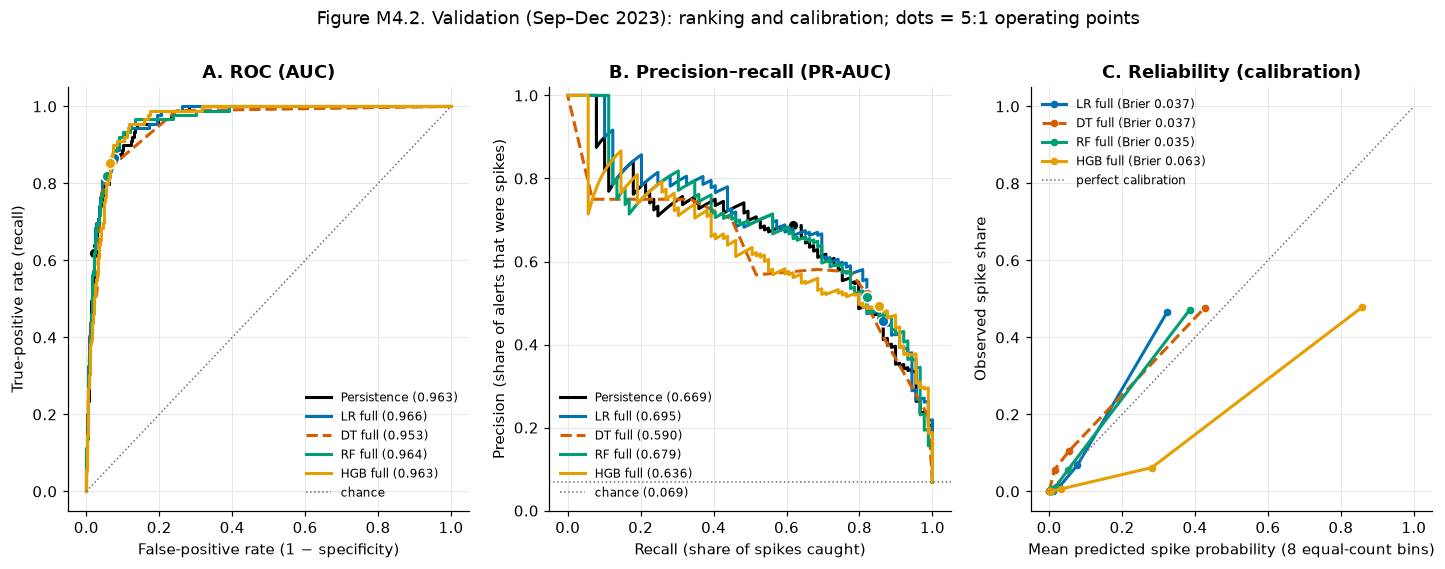

In [8]:
# Figure M4.2: ROC, precision-recall and reliability curves on validation
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

SHOW = ["persistence", "lr_full", "dt_full", "rf_full", "hgb_full"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for m in SHOW:
    fpr, tpr, _ = roc_curve(y_va, score_va[m])
    prec, rec, _ = precision_recall_curve(y_va, score_va[m])
    kw = dict(color=COLOR[m], lw=2.0, ls="--" if m == "dt_full" else "-")
    axes[0].plot(fpr, tpr, label=f"{LABEL[m]} ({boot.loc[(m, 'roc_auc'), 'estimate']:.3f})", **kw)
    axes[1].plot(rec, prec, label=f"{LABEL[m]} ({boot.loc[(m, 'pr_auc'), 'estimate']:.3f})", **kw)
    c = counts.loc[LABEL[m]]
    axes[0].plot(c.fp / (c.fp + c.tn), c.tp / (c.tp + c.fn), "o", color=COLOR[m], ms=7, mec="white")
    axes[1].plot(c.tp / (c.tp + c.fn), c.tp / max(c.tp + c.fp, 1), "o", color=COLOR[m], ms=7, mec="white")
    if m != "persistence":
        frac, mean_p = calibration_curve(y_va, score_va[m], n_bins=8, strategy="quantile")
        axes[2].plot(mean_p, frac, marker="o", ms=4, label=f"{LABEL[m]} (Brier {boot.loc[(m, 'brier'), 'estimate']:.3f})", **kw)
axes[0].plot([0, 1], [0, 1], color=P.GREY, ls=":", lw=1, label="chance")
axes[1].axhline(y_va.mean(), color=P.GREY, ls=":", lw=1, label=f"chance ({y_va.mean():.3f})")
axes[2].plot([0, 1], [0, 1], color=P.GREY, ls=":", lw=1, label="perfect calibration")
axes[0].set(xlabel="False-positive rate (1 − specificity)", ylabel="True-positive rate (recall)", title="A. ROC (AUC)")
axes[1].set(xlabel="Recall (share of spikes caught)", ylabel="Precision (share of alerts that were spikes)",
            title="B. Precision–recall (PR-AUC)", ylim=(0, 1.02))
axes[2].set(xlabel="Mean predicted spike probability (8 equal-count bins)", ylabel="Observed spike share",
            title="C. Reliability (calibration)")
for ax, loc in zip(axes, ["lower right", "lower left", "upper left"]):
    ax.legend(loc=loc, fontsize=8)
fig.suptitle("Figure M4.2. Validation (Sep–Dec 2023): ranking and calibration; dots = 5:1 operating points", y=1.02)
P.save(fig, "fig_m04_2_roc_pr_calibration")
plt.show()

             ratios_cheaper_than_persistence  break_even_ratio   cost_at_5  cost_at_20
LR full                                 19.0               2.0  117.103236  255.778120
DT full                                 19.0               2.0  113.251156  275.808937
RF full                                 19.0               2.0  114.791988  223.420647
HGB full                                18.0               3.0  110.169492  222.650231
Persistence                              NaN               NaN  150.231125  543.143297


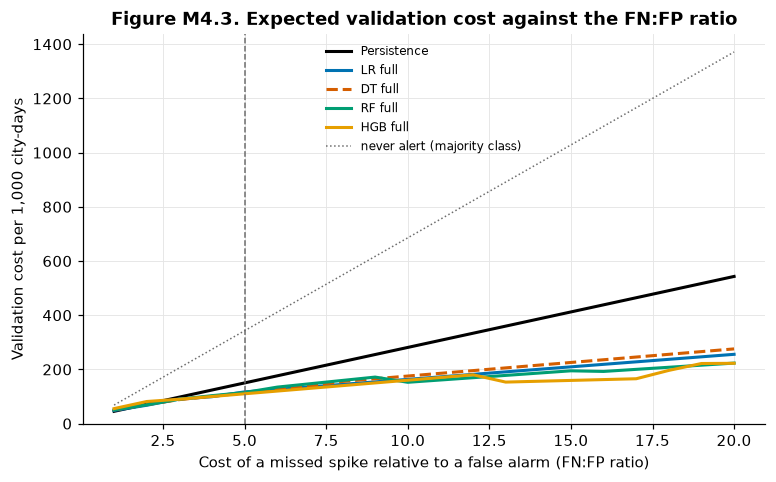

In [9]:
# Asymmetric cost: cost curve over FN:FP ratios 1-20 (thresholds re-chosen on OOF at each ratio)
curves = []
for m in ["lr_full", "dt_full", "rf_full", "hgb_full"]:
    curves.append(EV.cost_curve(y_tr, oof[m], y_va, score_va[m]).assign(model=LABEL[m]))
curves.append(EV.cost_curve(y_tr, None, y_va, None, yhat_val=pers_yhat_va).assign(model=LABEL["persistence"]))
cost_curve = pd.concat(curves, ignore_index=True)
_ = save_table(cost_curve, "m4_cost_curve", index=False)
pc = cost_curve[cost_curve.model == "Persistence"].set_index("ratio")["cost_per_1000"]
be = {}
for m in ["LR full", "DT full", "RF full", "HGB full"]:
    mc = cost_curve[cost_curve.model == m].set_index("ratio")["cost_per_1000"]
    cheaper = mc < pc
    be[m] = {"ratios_cheaper_than_persistence": int(cheaper.sum()),
             "break_even_ratio": int(cheaper.idxmax()) if cheaper.any() else None,
             "cost_at_5": mc[5], "cost_at_20": mc[20]}
be["Persistence"] = {"cost_at_5": pc[5], "cost_at_20": pc[20]}
print(pd.DataFrame(be).T.to_string())

fig, ax = plt.subplots(figsize=(8, 4.6))
for m in ["persistence", "lr_full", "dt_full", "rf_full", "hgb_full"]:
    d = cost_curve[cost_curve.model == LABEL[m]]
    ax.plot(d.ratio, d.cost_per_1000, color=COLOR[m], lw=2, ls="--" if m == "dt_full" else "-", label=LABEL[m])
d = cost_curve[cost_curve.model == "Persistence"]
ax.plot(d.ratio, d.never_alert, color=P.GREY, lw=1, ls=":", label="never alert (majority class)")
ax.axvline(5, color=P.GREY, lw=1, ls="--")
ax.set(xlabel="Cost of a missed spike relative to a false alarm (FN:FP ratio)",
       ylabel="Validation cost per 1,000 city-days", ylim=(0, None),
       title="Figure M4.3. Expected validation cost against the FN:FP ratio")
ax.legend(fontsize=8)
P.save(fig, "fig_m04_3_cost_curve")
plt.show()

**What we found (M4.3)**

- **Validation PR-AUC:** LR full 0.695, RF full 0.679, persistence 0.669, HGB full 0.636, DT full 0.590.
- **RF − LR:** −0.015 [−0.067, 0.015]. RF beats LR in 1 of 25 CV folds.
- **HGB − LR:** −0.059 [−0.116, −0.030]. This CI excludes 0, so HGB ranks spikes worse than LR.
- **The ensembles improve on the single tree, not on LR.** RF − DT is +0.090 [0.039, 0.125], and RF wins all 25 folds.
- **Cost at 5:1** (per 1,000 city-days): HGB 110.2, DT 113.3, RF 114.8, LR 117.1, persistence 150.2. The cost differences against LR have CIs that include 0.
- **Break-even ratio:** LR, DT and RF beat persistence from 2:1, HGB from 3:1.
- **Brier score:** RF 0.035, LR 0.037, HGB 0.063.

---
## M4.4 Do the ensembles find a fire signal? Drivers

- **Fire ablation:** RF and HGB with and without the four fire columns (pairs in the M4.3 table).
- **Grouped permutation importance** on validation (drop in PR-AUC, 30 repeats). Related columns are shuffled together, as in Milestone 3.

model                         HGB full  LR full  RF full
group                                                   
AQ history (today, lags 1–2)    0.5310   0.6121   0.5426
Mean temperature                0.0321   0.0423   0.0194
Humidity                        0.0137   0.0000   0.0069
Month                           0.0055   0.0000   0.0039
Upwind fires (t, lags 1–3)     -0.0104   0.0000   0.0028
Wind speed (vector)            -0.0118   0.0000   0.0005
Rain day                        0.0318   0.0000   0.0002
Wind direction                  0.0015   0.0000   0.0000
Stagnant (t, t−1)               0.0009   0.0000   0.0000
City                           -0.0020   0.0000  -0.0000
Temperature range              -0.0029   0.0000  -0.0028

                    comparison  metric  validation_diff    ci_low  ci_high  ci_excludes_0  cv_diff_mean  cv_folds_a_better
          RF full − RF no-fire  pr_auc           0.0030   -0.0068   0.0172          False       -0.0009               10.0
          RF

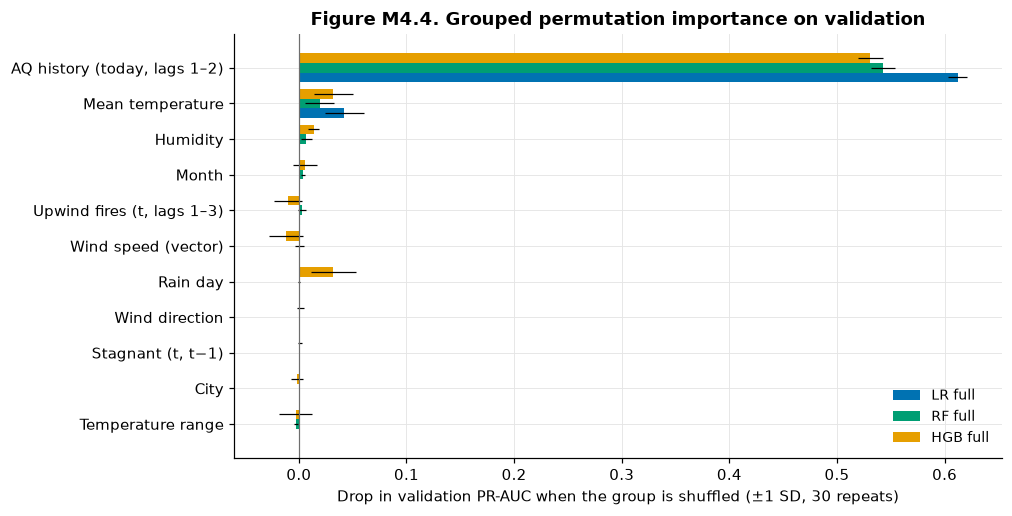

In [10]:
GROUPS = {"AQ history (today, lags 1–2)": MD.AQ_HISTORY, "Upwind fires (t, lags 1–3)": MD.FIRE,
          "Stagnant (t, t−1)": ["stagnant", "stagnant_lag1"], "Humidity": ["rh_mean_pct"],
          "Rain day": ["rain_day"], "Temperature range": ["temp_range_c"], "Wind speed (vector)": ["vec_len_kmh"],
          "Mean temperature": ["temp_mean_c"], "Wind direction": [c for c in MD.WEATHER if c.startswith("wind_from_")],
          "Month": MD.MONTHS, "City": MD.CITY_DUMMIES}


def group_permutation(model, X, y, groups, n_repeats=30, seed=42):
    # Drop in validation PR-AUC when all columns of a group are shuffled together
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = []
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out.append({"group": g, "mean": np.mean(drops), "sd": np.std(drops, ddof=1)})
    return pd.DataFrame(out)


imp = pd.concat([group_permutation(fitted[m], X_va["full"], y_va, GROUPS).assign(model=LABEL[m])
                 for m in ["lr_full", "rf_full", "hgb_full"]])
_ = save_table(imp, "m4_importance", index=False)
piv = imp.pivot(index="group", columns="model", values="mean").sort_values("RF full", ascending=False)
print(piv.round(4).to_string())
print()
print(deltas[deltas.comparison.str.contains("no-fire|weather-only")].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
order = piv.index[::-1]
for k, m in enumerate(["LR full", "RF full", "HGB full"]):
    d = imp[imp.model == m].set_index("group").loc[order]
    ax.barh(np.arange(len(order)) + (k - 1) * 0.27, d["mean"], height=0.27, xerr=d["sd"],
            color=[P.CAT_COLORS[0], P.CAT_COLORS[2], P.CAT_COLORS[3]][k], label=m, error_kw={"lw": 0.8})
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels(order)
ax.axvline(0, color=P.GREY, lw=0.8)
ax.set(xlabel="Drop in validation PR-AUC when the group is shuffled (±1 SD, 30 repeats)",
       title="Figure M4.4. Grouped permutation importance on validation")
ax.legend(loc="lower right")
P.save(fig, "fig_m04_4_importance")
plt.show()

**What we found (M4.4)**

- **AQ history drives all three models.** Shuffling it costs 0.612 (LR), 0.543 (RF) and 0.531 (HGB) of validation PR-AUC.
- Shuffling the fire columns costs 0.000 (LR), 0.003 (RF) and −0.010 (HGB).
- **Full − no-fire, PR-AUC:** RF +0.003 [−0.007, 0.017], better in 10 of 25 folds. HGB +0.011 [−0.013, 0.068], better in 8 of 25 folds.
- **Full − no-fire, cost:** the fire columns lower the 5:1 validation cost (RF −6.2 [−10.8, −2.2], HGB −12.3 [−25.4, −1.5]). For RF this is 8 fewer false alarms with the same 73 spikes caught.
- CV does not confirm a ranking gain, so the fire skill is not consistent. The validation cost gain rests on one season.
- **No-fire − weather-only:** RF +0.303, HGB +0.331. AQ history matters, fires do not.

---
## M4.5 Hypotheses H1, H3 and H4

Each test is an OLS regression of tomorrow's index (`target_index_h1`) on training rows, with city-clustered standard errors and a week-clustered check (as specified in Milestone 2, Table 12).
- **Controls (C):** month and city dummies, mean temperature, temperature range, humidity, rain total and vector-mean wind.
- **Spec A** is the Milestone 2 specification. **Spec B** adds today's index (`persist_index`), so it asks whether fires matter beyond today's smog.
- **H1 (cone vs radius):** the upwind-cone count next to the plain 300 km count; the downwind placebo cone in a separate run. H1: β_cone > 0.
- **H3 (fire × stagnation):** cone count × stagnant. H3: β_interaction > 0.
- **H4 (cross-border, 7 Pakistani cities):** India-origin cone fires, India-origin × near border (Lahore, Sialkot), Pakistan-origin cone fires. H4: β_IN > 0 and β_IN×near > 0.
- Fire counts enter as log1p z-scores (training parameters from Milestone 2). One-sided p-values follow the direction of each hypothesis.

In [11]:
import statsmodels.api as sm

CTRL = MD.MONTHS + ["temp_mean_c", "temp_range_c", "rh_mean_pct", "precip_sum_mm", "vec_len_kmh"]
CONE, RAD, DOWN = "fire_cnt_up45_r300_all_log1p_z", "fire_cnt_r300_all_log1p_z", "fire_cnt_down45_r300_all_log1p_z"
IN, PK = "fire_cnt_up45_r300_in_log1p_z", "fire_cnt_up45_r300_pk_log1p_z"
hyp = train.copy()
hyp["cone_x_stagnant"] = hyp[CONE] * hyp["stagnant"]
hyp["in_x_near"] = hyp[IN] * hyp["near_border"]
PK_CITY_DUMMIES = [c for c in MD.CITY_DUMMIES if c.replace("city_", "") in
                   [k.lower().replace(" ", "_") for k, v in C.CITY_COUNTRY.items() if v == "PK"]]
SPECS = {
    "H1": (hyp, [CONE, RAD], {CONE: "+"}, MD.CITY_DUMMIES),
    "H1 placebo": (hyp, [DOWN, RAD], {DOWN: "+"}, MD.CITY_DUMMIES),
    "H3": (hyp, [CONE, "stagnant", "cone_x_stagnant"], {"cone_x_stagnant": "+"}, MD.CITY_DUMMIES),
    "H4": (hyp[hyp.country == "PK"], [IN, "in_x_near", PK], {IN: "+", "in_x_near": "+"}, PK_CITY_DUMMIES),
}
rows = []
for h, (d, X_terms, tested, cities) in SPECS.items():
    for spec, extra in [("A: Milestone 2 spec", []), ("B: + today's index", ["persist_index"])]:
        Xh = sm.add_constant(d[X_terms + extra + CTRL + cities].astype(float))
        yh = d["target_index_h1"].astype(float)
        fc = sm.OLS(yh, Xh).fit(cov_type="cluster", cov_kwds={"groups": d["city"].astype("category").cat.codes})
        fw = sm.OLS(yh, Xh).fit(cov_type="cluster", cov_kwds={"groups": MD.week_groups(d["date"])})
        for t in X_terms:
            b, p2 = fc.params[t], fc.pvalues[t]
            rows.append({"hypothesis": h, "spec": spec, "term": t, "tested": t in tested, "coef": b,
                         "ci_low_city": fc.conf_int().loc[t, 0], "ci_high_city": fc.conf_int().loc[t, 1],
                         "p_one_sided_city": (p2 / 2 if b > 0 else 1 - p2 / 2) if t in tested else np.nan,
                         "p_two_sided_city": p2,
                         "ci_low_week": fw.conf_int().loc[t, 0], "ci_high_week": fw.conf_int().loc[t, 1],
                         "p_one_sided_week": (fw.pvalues[t] / 2 if b > 0 else 1 - fw.pvalues[t] / 2) if t in tested else np.nan,
                         "n": int(fc.nobs), "clusters_city": d["city"].nunique(), "r2": fc.rsquared})
hyp_tab = pd.DataFrame(rows)
_ = save_table(hyp_tab, "m4_hypotheses", index=False)
print(hyp_tab.drop(columns=["ci_low_week", "ci_high_week"]).round(4).to_string(index=False))

hypothesis                spec                             term  tested    coef  ci_low_city  ci_high_city  p_one_sided_city  p_two_sided_city  p_one_sided_week    n  clusters_city     r2
        H1 A: Milestone 2 spec   fire_cnt_up45_r300_all_log1p_z    True  0.0543       0.0074        0.1012            0.0116            0.0231            0.0010 4246             11 0.6356
        H1 A: Milestone 2 spec        fire_cnt_r300_all_log1p_z   False -0.0227      -0.0576        0.0122               NaN            0.2021               NaN 4246             11 0.6356
        H1  B: + today's index   fire_cnt_up45_r300_all_log1p_z    True  0.0351       0.0116        0.0586            0.0017            0.0035            0.0014 4246             11 0.7837
        H1  B: + today's index        fire_cnt_r300_all_log1p_z   False -0.0218      -0.0379       -0.0057               NaN            0.0079               NaN 4246             11 0.7837
H1 placebo A: Milestone 2 spec fire_cnt_down45_r300_all_log1

**What we found (M4.5)**

- **H1 supported.** Upwind-cone fires raise the next-day index beyond the radius count: β = 0.054 [0.007, 0.101], one-sided p = 0.012.
  - With today's index added (spec B): β = 0.035, p = 0.002.
  - The downwind placebo cone is not positive (β = −0.032, p = 0.97).
- **H3 not supported.** The fire × stagnation term is negative: −0.038 [−0.091, 0.015] in spec A and −0.045 [−0.073, −0.017] in spec B.
  - On stagnant days the cone count equals the radius count (DECISIONS.md), so the interaction compares two different fire measures.
- **H4 not supported.** India-origin fires show no association in Pakistani cities (β = 0.001, p = 0.48). The near-border term is 0.002 (p = 0.46).
  - Pakistan-origin fires do: β = 0.056 [0.019, 0.093].
  - H4 has only 7 city clusters, so its CIs are approximate.

---
## M4.6 Fairness audit

**Positive prediction = an alert for tomorrow.** For every group we report:
- **Selection rate** (share of city-days with an alert) and the **disparate impact ratio (DIR)** against the reference group. The 80% rule is read two-sided (0.8–1.25), because an alert both protects (fewer missed spikes) and costs (false alarms).
- **Equal opportunity:** the gap in true-positive rate (TPR, recall).
- **Predictive equality:** the gap in false-positive rate (FPR, false alarms on clean days).
- **Equalized odds difference:** the larger of the two gaps.
- **Demographic parity difference:** the gap in selection rate.

**Two audit sets.** Validation (89 spikes) is the honest test. The out-of-fold training predictions (204 spikes, 25 folds) give a second, larger look with the same thresholds. Gaps are max − min over groups. CIs come from the week-block bootstrap. City-level results are descriptive.

**Base rates.** Each city's spike label is the top 10% of its own training October–March days, so base rates are equal by design in training October–March. Demographic parity is therefore more meaningful here than in most audits. Validation base rates differ by group, so parity there is read together with equalized odds.

In [12]:
oof_frame = train[["city", "country", "country_name", "tier", "date", TARGET]].copy()
oof_frame["s_persistence"], oof_frame["p_persistence"] = pers_score_tr, pers_yhat_tr
for m in oof:
    oof_frame[f"s_{m}"], oof_frame[f"p_{m}"] = oof[m], (oof[m] >= thresholds[m]).astype(int)
AUDIT_SETS = {"validation": vframe, "training OOF": oof_frame}

grp_rows, disp_rows = [], []
for data, frame in AUDIT_SETS.items():
    for m in AUDIT:
        for col in GROUPINGS:
            gm = FA.group_metrics(frame[TARGET], frame[f"p_{m}"], frame[col]).reset_index()
            grp_rows.append(gm.assign(model=LABEL[m], data=data, grouping=GROUPINGS[col]))
            point = FA.disparity(gm.set_index("group"), PRIV[col])
            if col == "city":
                for k, v in point.items():
                    disp_rows.append({"model": LABEL[m], "data": data, "grouping": GROUPINGS[col], "metric": k,
                                      "estimate": float(v), "ci_low": np.nan, "ci_high": np.nan})
                continue
            bb = EV.block_bootstrap(frame, FA.disparity_fn(TARGET, f"p_{m}", col, PRIV[col]), n=N_BOOT, seed=42)
            for k, r in bb.iterrows():
                disp_rows.append({"model": LABEL[m], "data": data, "grouping": GROUPINGS[col], "metric": k,
                                  "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high})
            disp_rows.append({"model": LABEL[m], "data": data, "grouping": GROUPINGS[col], "metric": "passes_80_rule",
                              "estimate": float(point["passes_80_rule"]), "ci_low": np.nan, "ci_high": np.nan})
fair_groups = pd.concat(grp_rows, ignore_index=True)
fair_disp = pd.DataFrame(disp_rows)
_ = save_table(fair_groups, "m4_fair_groups", index=False)
_ = save_table(fair_disp, "m4_fair_disparity", index=False)

show_cols = ["group", "n", "spikes", "base_rate", "selection_rate", "tpr", "fpr", "precision", "cost_per_1000"]
for data in AUDIT_SETS:
    for g in ["city-size tier", "country"]:
        print(f"\n{data}, by {g}")
        d = fair_groups[(fair_groups.data == data) & (fair_groups.grouping == g)]
        print(d.set_index("model")[show_cols].astype({c: float for c in show_cols[1:]}).round(3).to_string())
print()
show = fair_disp[fair_disp.grouping != "city"].assign(
    value=lambda d: d.estimate.round(3).astype(str) + np.where(d.ci_low.notna(), " [" + d.ci_low.round(3).astype(str)
                                                               + ", " + d.ci_high.round(3).astype(str) + "]", ""))
print(show.pivot_table(index=["data", "grouping", "model"], columns="metric", values="value", aggfunc="first")
      [["dir_vs_priv_min", "dir_vs_priv_max", "passes_80_rule", "eop_diff", "pe_diff", "eo_diff", "dp_diff"]].to_string())


validation, by city-size tier
                            group      n  spikes  base_rate  selection_rate    tpr    fpr  precision  cost_per_1000
model                                                                                                              
Persistence  Tier 1 metro (≥ 3 M)  354.0    12.0      0.034           0.028  0.500  0.012      0.600         96.045
Persistence  Tier 2 large (1–3 M)  472.0    25.0      0.053           0.047  0.560  0.018      0.636        133.475
Persistence  Tier 3 small (< 1 M)  472.0    52.0      0.110           0.102  0.673  0.031      0.729        207.627
LR full      Tier 1 metro (≥ 3 M)  354.0    12.0      0.034           0.079  0.750  0.056      0.321         96.045
LR full      Tier 2 large (1–3 M)  472.0    25.0      0.053           0.106  0.840  0.065      0.420        103.814
LR full      Tier 3 small (< 1 M)  472.0    52.0      0.110           0.193  0.904  0.105      0.516        146.186
RF full      Tier 1 metro (≥ 3 M)  354.0 

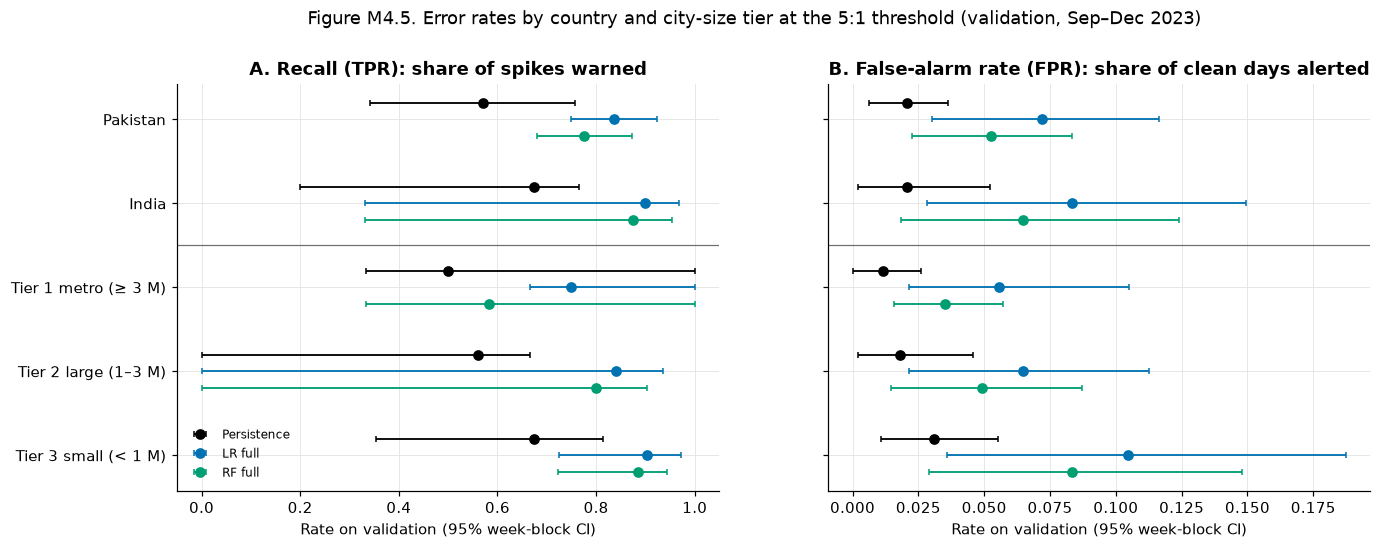

In [13]:
# Per-group error rates with 95% week-block CIs (validation), for the figure
ci_rows = []
for m in AUDIT:
    for col in ["country_name", "tier"]:
        for g in sorted(vframe[col].unique()):
            sub = vframe[vframe[col] == g]
            fn = lambda d: {k: v for k, v in FA._rates(d[TARGET], d[f"p_{m}"]).items() if k in ("tpr", "fpr", "selection_rate")}
            bb = EV.block_bootstrap(sub, fn, n=N_BOOT, seed=42)
            for k, r in bb.iterrows():
                ci_rows.append({"model": LABEL[m], "grouping": GROUPINGS[col], "group": g, "metric": k,
                                "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high})
group_ci = pd.DataFrame(ci_rows)
_ = save_table(group_ci, "m4_fair_group_ci", index=False)

# Figure M4.5: recall (TPR) and false-alarm rate (FPR) by group, validation
glist = ["Pakistan", "India"] + [FA.TIER_LABEL[k] for k in (1, 2, 3)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, metric, title in [(axes[0], "tpr", "A. Recall (TPR): share of spikes warned"),
                          (axes[1], "fpr", "B. False-alarm rate (FPR): share of clean days alerted")]:
    for k, m in enumerate(AUDIT):
        d = group_ci[(group_ci.model == LABEL[m]) & (group_ci.metric == metric)].set_index("group").loc[glist]
        yv = np.arange(len(glist)) + (k - (len(AUDIT) - 1) / 2) * 0.2
        ax.errorbar(d["estimate"], yv, xerr=[d["estimate"] - d["ci_low"], d["ci_high"] - d["estimate"]],
                    fmt="o", color=COLOR[m], ms=6, capsize=2, lw=1.2, label=LABEL[m])
    ax.axhline(1.5, color=P.GREY, lw=0.8)
    ax.set_yticks(range(len(glist))); ax.set_yticklabels(glist)
    ax.set(xlabel="Rate on validation (95% week-block CI)", title=title)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure M4.5. Error rates by country and city-size tier at the 5:1 threshold (validation, Sep–Dec 2023)", y=1.02)
P.save(fig, "fig_m04_5_group_rates")
plt.show()

**What we found (M4.6)**

- **Country.** LR full warns of 83.7% of Pakistani and 90.0% of Indian spikes. Its false-alarm rates are 7.2% and 8.3%. The equalized-odds gap is 0.063 [0.004, 0.471].
  - The country DIR is 1.30 on validation and fails the two-sided rule. India's base rate was 1.43 times Pakistan's, so the extra alerts follow the spikes.
- **City-size tier.** LR full raises false alarms on 5.6% (Tier 1), 6.5% (Tier 2) and 10.5% (Tier 3) of clean days. The predictive-equality gap is 0.049 [0.011, 0.126].
  - Persistence shows the same direction: 1.2% against 3.1%.
  - The DIR reaches 2.44 for Tier 3 and fails the rule. The base-rate ratio is 3.25, so a perfect alert would fail it by more.
- **Training OOF.** LR full passes the 80% rule by tier (1.15–1.18) and by country (1.01). The tier FPR gap is only 0.017.
- **RF full has a larger tier gap than LR** on validation (equalized odds 0.301 against 0.154). Its metro recall is 0.583, from 7 of 12 spikes.
- **City.** The highest false-alarm rates are in Rahim Yar Khan (16.7%), Multan (13.0%) and Faisalabad (12.2%). Islamabad and Rawalpindi had no spike and 1.7%.

---
## M4.7 Bias mitigation

Mitigation targets the **city-size tier**, the attribute the instructor suggested. All choices use OOF training predictions only.

| Method | Stage | What changes |
|---|---|---|
| Reweighing (Kamiran and Calders, 2012) | pre-processing | Training rows get weights P(tier)·P(label)/P(tier, label), so tier and label are independent in the fit. Weights are computed inside each CV fold from its fit rows. |
| Cost-optimal threshold per tier | post-processing | Each tier gets its own 5:1 threshold (asymmetric threshold tuning per group). |
| Predictive-equality thresholds | post-processing | Tier thresholds that minimise total 5:1 cost while every tier's FPR stays within ±ε/2 of a common value. |
| Equalized-odds thresholds (Hardt et al., 2016) | post-processing | The same, with the band on both FPR and TPR. |

The headline band is **ε = 0.05** (fixed before results). Section M4.8 sweeps ε.

In [14]:
def weight_fn_for(alpha, groups):
    # Reweighing weights for one fold, computed from that fold's fit rows only
    return lambda fit_idx: FA.reweigh_weights(groups[fit_idx], y_tr[fit_idx], alpha)


tier_tr, tier_va = train["tier"].to_numpy(), val["tier"].to_numpy()
rw = {}                                                # reweighed models: OOF, refit, validation scores
for m in MITIGATE:
    s = m.split("_", 1)[1]
    assert_train_only(train)
    p_oof, _ = MD.oof_predict(fitted[m], X_tr[s], y_tr, splits, weight_fn=weight_fn_for(1.0, tier_tr))
    est = clone(fitted[m]).fit(X_tr[s], y_tr, model__sample_weight=FA.reweigh_weights(tier_tr, y_tr, 1.0))
    rw[m] = {"oof": p_oof, "est": est, "val": est.predict_proba(X_va[s])[:, 1]}
w_all = FA.reweigh_weights(tier_tr, y_tr, 1.0)
print(f"Reweighing weights on all training rows (alpha = 1): {w_all.min():.3f} to {w_all.max():.3f}")


mit_grp_rows = []


def evaluate_rule(name, m, yhat_tr, yhat_va, thr):
    out = []
    for data, y, yh, g in [("training OOF", y_tr, yhat_tr, tier_tr), ("validation", y_va, yhat_va, tier_va)]:
        r = EV.binary_metrics(y, yh.astype(float), yhat=yh)
        mit_grp_rows.append(FA.group_metrics(y, yh, g).reset_index().assign(model=LABEL[m], method=name, data=data))
        dsp = FA.disparity(FA.group_metrics(y, yh, g), PRIV["tier"])
        out.append({"model": LABEL[m], "method": name, "data": data, "thresholds": json.dumps(thr),
                    **{k: r[k] for k in ["accuracy", "precision", "recall", "specificity", "f1", "cost_per_1000"]},
                    **dsp})
    return out


mit_rows, MIT_RULES = [], {}
for m in MITIGATE:
    p_tr, p_va = oof[m], score_va[m]
    single = {g: thresholds[m] for g in FA.TIER_LABEL.values()}
    rules = {"none (single threshold)": (p_tr, p_va, single)}
    t_rw, _ = MD.choose_threshold(y_tr, rw[m]["oof"], COST_FN, COST_FP)
    rules["reweighing (pre-processing)"] = (rw[m]["oof"], rw[m]["val"], {g: t_rw for g in FA.TIER_LABEL.values()})
    rules["threshold per tier, cost-optimal"] = (p_tr, p_va, FA.group_thresholds(y_tr, p_tr, tier_tr, COST_FN, COST_FP))
    thr_pe, _ = FA.constrained_thresholds(y_tr, p_tr, tier_tr, EPS_HEADLINE, "fpr", COST_FN, COST_FP)
    rules[f"predictive equality, ε = {EPS_HEADLINE}"] = (p_tr, p_va, thr_pe)
    thr_eo, _ = FA.constrained_thresholds(y_tr, p_tr, tier_tr, EPS_HEADLINE, "eo", COST_FN, COST_FP)
    rules[f"equalized odds, ε = {EPS_HEADLINE}"] = (p_tr, p_va, thr_eo)
    MIT_RULES[m] = rules
    for name, (a, b, thr) in rules.items():
        assert thr is not None, f"{name}: no feasible thresholds"
        mit_rows += evaluate_rule(name, m, FA.apply_thresholds(a, tier_tr, thr), FA.apply_thresholds(b, tier_va, thr),
                                  {k: round(v, 4) for k, v in thr.items()})
mitigation = pd.DataFrame(mit_rows)
_ = save_table(mitigation, "m4_mitigation", index=False)
mitigation_groups = pd.concat(mit_grp_rows, ignore_index=True)
_ = save_table(mitigation_groups, "m4_mitigation_groups", index=False)
print(mitigation[["model", "method", "data", "recall", "precision", "f1", "cost_per_1000", "dir_vs_priv_min",
                  "dir_vs_priv_max", "eop_diff", "pe_diff", "eo_diff"]].round(3).to_string(index=False))
print()
for m in MITIGATE:
    for name, (_, _, thr) in MIT_RULES[m].items():
        print(f"{LABEL[m]:<9} {name:<36} " + ", ".join(f"{k.split(' (')[0]}: {v:.4f}" for k, v in thr.items()))

Reweighing weights on all training rows (alpha = 1): 0.976 to 1.045


  model                           method         data  recall  precision    f1  cost_per_1000  dir_vs_priv_min  dir_vs_priv_max  eop_diff  pe_diff  eo_diff
LR full          none (single threshold) training OOF   0.941      0.397 0.558         82.902            1.150            1.176     0.091    0.017    0.091
LR full          none (single threshold)   validation   0.865      0.456 0.597        117.103            1.339            2.438     0.154    0.049    0.154
LR full      reweighing (pre-processing) training OOF   0.941      0.398 0.559         82.666            1.160            1.186     0.091    0.018    0.091
LR full      reweighing (pre-processing)   validation   0.865      0.456 0.597        117.103            1.339            2.438     0.154    0.049    0.154
LR full threshold per tier, cost-optimal training OOF   0.926      0.423 0.581         78.427            0.944            1.196     0.049    0.024    0.049
LR full threshold per tier, cost-optimal   validation   0.854   

**What we found (M4.7)**

- **Per-tier thresholds for LR full:** Tier 1 0.131, Tier 2 0.128, Tier 3 0.160 (single threshold 0.128).
- On validation they cut the Tier 3 false-alarm rate from 10.5% to 8.1% (44 to 34 false alarms).
  - The predictive-equality gap falls from 0.049 to 0.025.
  - The cost falls from 117.1 to 113.3, and F1 rises from 0.597 to 0.615.
  - Recall drops from 0.865 to 0.854 (one more missed spike).
- At ε = 0.05, the predictive-equality and equalized-odds rules give LR full the same validation result. On OOF, equalized odds cuts the gap from 0.091 to 0.026.
- **Reweighing changes little.** The tiers have nearly equal training base rates, so the weights stay between 0.98 and 1.05. LR full alerts are unchanged on validation. RF full cost moves from 114.8 to 112.5, and its gap stays at 0.301.
- **Per-tier thresholds do not transfer for RF full.** Its validation cost rises from 114.8 to 124.8, and recall falls from 0.820 to 0.775.
- The tier DIR still fails on validation (2.14), because the base rates differ.

---
## M4.8 Fairness–accuracy trade-off (Pareto frontier)

- **Sweep:** ε from 0.01 to 0.20 for the predictive-equality and equalized-odds thresholds; reweighing strength α ∈ {0, 0.25, 0.5, 0.75, 1}; plus the single and the per-tier cost-optimal thresholds.
- Every point's thresholds come from OOF training predictions. Each point is scored on OOF training rows and on validation.
- **Axes:** cost per 1,000 city-days at 5:1 (lower is better) against the equalized-odds gap between tiers (lower is fairer).
- A point is **Pareto-efficient** when no other point is both cheaper and fairer.

In [15]:
par_rows = []


def add_point(m, method, knob, p_tr, p_va, thr):
    if thr is None:
        return
    for data, y, p, g in [("training OOF", y_tr, p_tr, tier_tr), ("validation", y_va, p_va, tier_va)]:
        yh = FA.apply_thresholds(p, g, thr)
        r = EV.binary_metrics(y, yh.astype(float), yhat=yh)
        dsp = FA.disparity(FA.group_metrics(y, yh, g), PRIV["tier"])
        par_rows.append({"model": LABEL[m], "method": method, "knob": knob, "data": data,
                         "cost_per_1000": r["cost_per_1000"], "f1": r["f1"], "accuracy": r["accuracy"],
                         "recall": r["recall"], "eo_diff": dsp["eo_diff"], "pe_diff": dsp["pe_diff"],
                         "eop_diff": dsp["eop_diff"], "dir_vs_priv_min": dsp["dir_vs_priv_min"]})


EPS_GRID = np.round(np.arange(0.01, 0.2001, 0.01), 2)
for m in MITIGATE:
    s = m.split("_", 1)[1]
    p_tr, p_va = oof[m], score_va[m]
    add_point(m, "single threshold", np.nan, p_tr, p_va, {g: thresholds[m] for g in FA.TIER_LABEL.values()})
    add_point(m, "threshold per tier", np.nan, p_tr, p_va, FA.group_thresholds(y_tr, p_tr, tier_tr, COST_FN, COST_FP))
    for eps in EPS_GRID:
        for kind, name in [("fpr", "predictive equality"), ("eo", "equalized odds")]:
            thr, _ = FA.constrained_thresholds(y_tr, p_tr, tier_tr, eps, kind, COST_FN, COST_FP)
            add_point(m, name, eps, p_tr, p_va, thr)
    for alpha in [0.25, 0.5, 0.75, 1.0]:
        if alpha == 1.0:
            a_oof, a_val = rw[m]["oof"], rw[m]["val"]
        else:
            a_oof, _ = MD.oof_predict(fitted[m], X_tr[s], y_tr, splits, weight_fn=weight_fn_for(alpha, tier_tr))
            a_val = clone(fitted[m]).fit(X_tr[s], y_tr, model__sample_weight=FA.reweigh_weights(tier_tr, y_tr, alpha)
                                         ).predict_proba(X_va[s])[:, 1]
        t_a, _ = MD.choose_threshold(y_tr, a_oof, COST_FN, COST_FP)
        add_point(m, "reweighing", alpha, a_oof, a_val, {g: t_a for g in FA.TIER_LABEL.values()})
pareto = pd.DataFrame(par_rows)
pareto["pareto"] = False
for (m, data), d in pareto.groupby(["model", "data"]):
    pareto.loc[d.index, "pareto"] = FA.pareto_mask(d["cost_per_1000"], d["eo_diff"])
_ = save_table(pareto, "m4_pareto", index=False)
front = (pareto[pareto.pareto].round(4).drop_duplicates(["model", "data", "cost_per_1000", "eo_diff"])
         .sort_values(["model", "data", "eo_diff"]))
print("Pareto-efficient points (duplicates with the same cost and gap shown once):")
print(front.round(3).to_string(index=False))

Pareto-efficient points (duplicates with the same cost and gap shown once):
  model              method  knob         data  cost_per_1000    f1  accuracy  recall  eo_diff  pe_diff  eop_diff  dir_vs_priv_min  pareto
LR full      equalized odds  0.01 training OOF        169.336 0.444     0.962   0.319    0.008    0.006     0.008            0.779    True
LR full      equalized odds  0.02 training OOF         82.902 0.584     0.940   0.882    0.017    0.017     0.010            0.919    True
LR full      equalized odds  0.03 training OOF         82.430 0.577     0.936   0.902    0.021    0.021     0.013            0.912    True
LR full      equalized odds  0.05 training OOF         80.782 0.578     0.936   0.912    0.026    0.022     0.026            0.925    True
LR full  threshold per tier   NaN training OOF         78.427 0.581     0.936   0.926    0.049    0.024     0.049            0.944    True
LR full predictive equality  0.01   validation        109.399 0.636     0.934   0.843    0

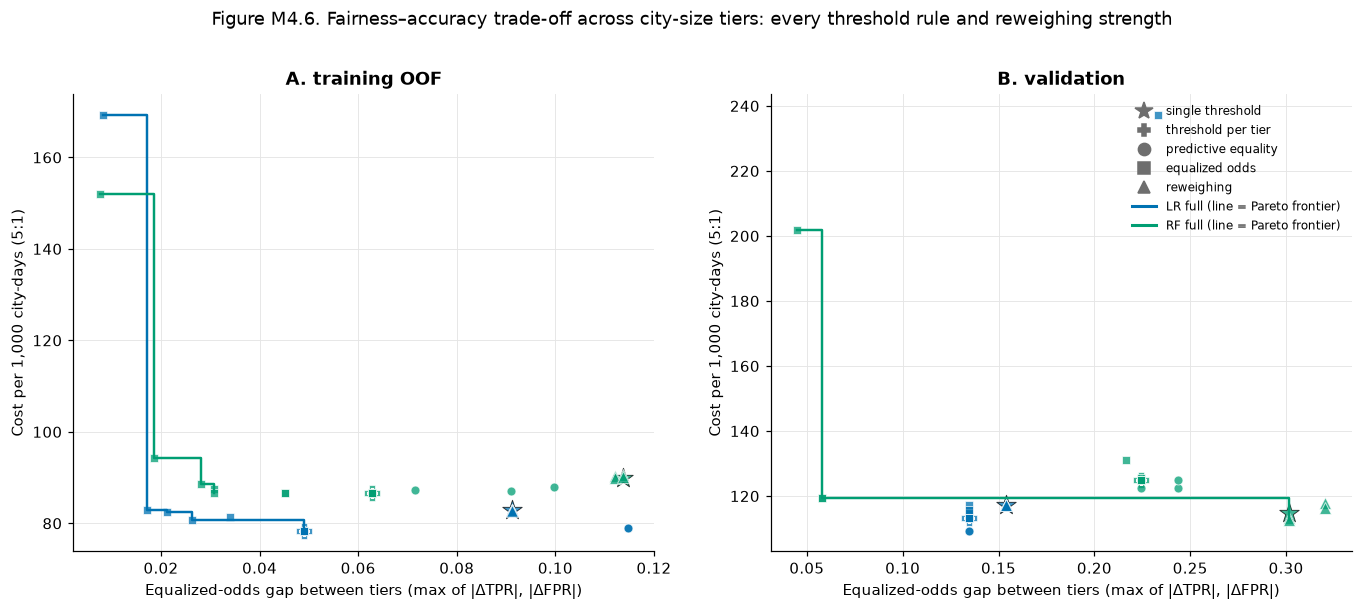

In [16]:
# Figure M4.6: Pareto frontier, cost vs equalized-odds gap between tiers
MK = {"single threshold": ("*", 180), "threshold per tier": ("P", 110), "predictive equality": ("o", 34),
      "equalized odds": ("s", 34), "reweighing": ("^", 60)}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, data in zip(axes, ["training OOF", "validation"]):
    for m in MITIGATE:
        d = pareto[(pareto.model == LABEL[m]) & (pareto.data == data)]
        for meth, (mk, sz) in MK.items():
            e = d[d.method == meth]
            ax.scatter(e["eo_diff"], e["cost_per_1000"], marker=mk, s=sz, color=COLOR[m], alpha=0.75,
                       edgecolor="white" if mk != "*" else "#000000", lw=0.6)
        f = d[d.pareto].sort_values("eo_diff")
        ax.step(f["eo_diff"], f["cost_per_1000"], where="post", color=COLOR[m], lw=1.6)
    ax.set(xlabel="Equalized-odds gap between tiers (max of |ΔTPR|, |ΔFPR|)", ylabel="Cost per 1,000 city-days (5:1)",
           title=f"{'A' if data == 'training OOF' else 'B'}. {data}")
handles = [Line2D([], [], marker=mk, ls="", color=P.GREY, ms=8 if mk != "*" else 12, label=meth) for meth, (mk, _) in MK.items()]
handles += [Line2D([], [], color=COLOR[m], lw=2, label=f"{LABEL[m]} (line = Pareto frontier)") for m in MITIGATE]
axes[1].legend(handles=handles, fontsize=8, loc="upper right")
fig.suptitle("Figure M4.6. Fairness–accuracy trade-off across city-size tiers: every threshold rule and reweighing strength", y=1.02)
P.save(fig, "fig_m04_6_pareto")
plt.show()

**What we found (M4.8)**

- **Training OOF, LR full:** tightening the equalized-odds band from ε = 0.05 to 0.02 lowers the gap from 0.026 to 0.017. The cost rises only from 80.8 to 82.9.
- At ε = 0.01 the cost jumps to 169.3, because recall falls to 0.319.
- The per-tier cost-optimal rule is the cheapest OOF point (78.4) with a gap of 0.049.
- **Validation:** the cheapest LR rule is predictive equality at ε = 0.01 (109.4). We did not choose it, because every choice must come from training data.
- Gaps chosen on OOF do not hold on validation: the LR equalized-odds gap stays at 0.135. The validation base rates differ by tier, and the metros have only 12 spikes.

---
## M4.9 Threshold curves and asymmetric costs by tier

- **A:** recall (TPR) and false-alarm rate (FPR) against the alert threshold, per tier, on OOF training predictions of the final model. Markers show the single 5:1 threshold and the per-tier thresholds.
- **B:** the cost-optimal threshold per tier for every FN:FP ratio from 1 to 20, and the resulting validation cost per tier.

  model                 tier  ratio     rule  threshold  val_fn  val_fp  val_cost_per_1000
LR full Tier 1 metro (≥ 3 M)      1 per tier     0.4729      10       1            31.0734
LR full Tier 1 metro (≥ 3 M)      1   single     0.4152       8       1            25.4237
LR full Tier 1 metro (≥ 3 M)      2 per tier     0.2351       6       5            48.0226
LR full Tier 1 metro (≥ 3 M)      2   single     0.2599       6       4            45.1977
LR full Tier 1 metro (≥ 3 M)      5 per tier     0.1305       3      19            96.0452
LR full Tier 1 metro (≥ 3 M)      5   single     0.1280       3      19            96.0452
LR full Tier 1 metro (≥ 3 M)     10 per tier     0.1305       3      19           138.4181
LR full Tier 1 metro (≥ 3 M)     10   single     0.1280       3      19           138.4181
LR full Tier 1 metro (≥ 3 M)     20 per tier     0.1305       3      19           223.1638
LR full Tier 1 metro (≥ 3 M)     20   single     0.1280       3      19           223.1638

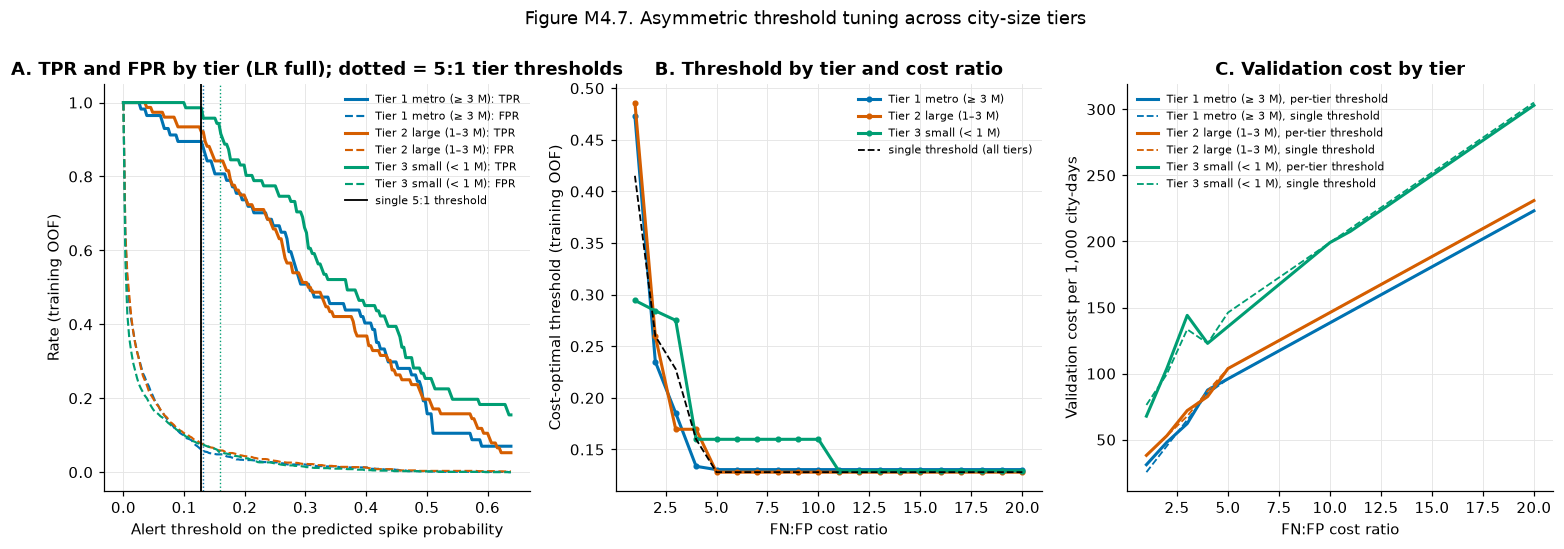

In [17]:
thr_rows = []
p_tr, p_va = oof[FINAL], score_va[FINAL]
for g in FA.TIER_LABEL.values():
    mtr, mva = tier_tr == g, tier_va == g
    for r in range(1, 21):
        t, _ = MD.choose_threshold(y_tr[mtr], p_tr[mtr], r, 1)
        t_all, _ = MD.choose_threshold(y_tr, p_tr, r, 1)
        for name, tt in [("per tier", t), ("single", t_all)]:
            yh = (p_va[mva] >= tt).astype(int)
            fn = int(((yh == 0) & (y_va[mva] == 1)).sum()); fp = int(((yh == 1) & (y_va[mva] == 0)).sum())
            thr_rows.append({"model": LABEL[FINAL], "tier": g, "ratio": r, "rule": name, "threshold": tt,
                             "val_fn": fn, "val_fp": fp, "val_cost_per_1000": 1000 * (r * fn + fp) / mva.sum()})
thr_curves = pd.DataFrame(thr_rows)
_ = save_table(thr_curves, "m4_threshold_curves", index=False)
print(thr_curves[thr_curves.ratio.isin([1, 2, 5, 10, 20])].round(4).to_string(index=False))

TIER_COLOR = dict(zip(FA.TIER_LABEL.values(), [P.CAT_COLORS[0], P.CAT_COLORS[1], P.CAT_COLORS[2]]))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
grid = np.linspace(0, max(0.6, np.quantile(p_tr, 0.995)), 200)
per_tier = FA.group_thresholds(y_tr, p_tr, tier_tr, COST_FN, COST_FP)
for g, col in TIER_COLOR.items():
    mk = tier_tr == g
    tpr = [(p_tr[mk & (y_tr == 1)] >= t).mean() for t in grid]
    fpr = [(p_tr[mk & (y_tr == 0)] >= t).mean() for t in grid]
    axes[0].plot(grid, tpr, color=col, lw=2, label=f"{g}: TPR")
    axes[0].plot(grid, fpr, color=col, lw=1.4, ls="--", label=f"{g}: FPR")
    axes[0].axvline(per_tier[g], color=col, lw=0.9, ls=":")
    d = thr_curves[(thr_curves.tier == g) & (thr_curves.rule == "per tier")]
    axes[1].plot(d.ratio, d.threshold, color=col, lw=2, marker="o", ms=3, label=g)
    axes[2].plot(d.ratio, d.val_cost_per_1000, color=col, lw=2, label=f"{g}, per-tier threshold")
    d1 = thr_curves[(thr_curves.tier == g) & (thr_curves.rule == "single")]
    axes[2].plot(d1.ratio, d1.val_cost_per_1000, color=col, lw=1.2, ls="--", label=f"{g}, single threshold")
axes[0].axvline(thresholds[FINAL], color="#000000", lw=1.2, label="single 5:1 threshold")
d = thr_curves[(thr_curves.tier == FA.TIER_LABEL[1]) & (thr_curves.rule == "single")]
axes[1].plot(d.ratio, d.threshold, color="#000000", lw=1.2, ls="--", label="single threshold (all tiers)")
axes[0].set(xlabel="Alert threshold on the predicted spike probability", ylabel="Rate (training OOF)",
            title=f"A. TPR and FPR by tier ({LABEL[FINAL]}); dotted = 5:1 tier thresholds")
axes[1].set(xlabel="FN:FP cost ratio", ylabel="Cost-optimal threshold (training OOF)", title="B. Threshold by tier and cost ratio")
axes[2].set(xlabel="FN:FP cost ratio", ylabel="Validation cost per 1,000 city-days", title="C. Validation cost by tier")
for ax in axes:
    ax.legend(fontsize=7)
fig.suptitle("Figure M4.7. Asymmetric threshold tuning across city-size tiers", y=1.02)
P.save(fig, "fig_m04_7_thresholds")
plt.show()

**What we found (M4.9)**

- **5:1 thresholds for LR full:** Tier 1 0.131, Tier 2 0.128, Tier 3 0.160.
- In every tier, the cost-optimal threshold falls or stays level as the cost ratio rises. For Tier 3 it falls from 0.295 at 1:1 to 0.129 at 20:1.
- Per-tier thresholds lower the Tier 3 validation cost at 5:1 (146.2 to 135.6) and at 1:1 (76.3 to 67.8). At 2:1 they raise it (99.6 to 103.8).
- For Tier 1 and Tier 2 the two rules give the same validation cost at 5:1, 10:1 and 20:1.

---
## M4.10 Model artifacts

- RF and HGB pipelines (3 feature sets each) → `models/rf_*.joblib`, `models/hgb_*.joblib`.
- The final model stays `models/lr_full.joblib` (Milestone 3). The per-tier thresholds of every mitigation rule go to `m4_params.json` (`mitigation_thresholds`).
- Search results, thresholds and choices → `Dataset/clean/m4_params.json`.

In [18]:
import platform
import scipy
import sklearn
import statsmodels

for m in searches:
    joblib.dump(fitted[m], f"models/{m}.joblib")

to_py = lambda v: None if v is None else (float(v) if isinstance(v, (float, np.floating)) else
                                          int(v) if isinstance(v, (int, np.integer)) else v)
params = {
    "target": TARGET, "cost_fn_fp": [COST_FN, COST_FP], "cv": m3["cv"],
    "search": {"type": "RandomizedSearchCV", "n_iter": MD.N_ITER, "seed": 42, "scoring": "average_precision",
               "hgb_early_stopping": False},
    "models": {m: {"best_params": {k.replace("model__", ""): to_py(v) for k, v in rs.best_params_.items()},
                   "cv_pr_auc": float(rs.best_score_), "threshold": thresholds[m]} for m, rs in searches.items()},
    "final_model_rule": "highest CV PR-AUC among full-feature LR, DT, RF, HGB; within 0.005 = tie; simplest tied model wins",
    "final_model": FINAL, "best_ensemble": BEST_ADV,
    "fairness": {"attribute": "geography", "groups": {"country": ["Pakistan", "India"], "tier": list(FA.TIER_LABEL.values()),
                 "city": sorted(train.city.unique())}, "privileged": PRIV, "eps_headline": EPS_HEADLINE,
                 "eighty_percent_rule": "two-sided, 0.8 to 1.25"},
    "mitigation_thresholds": {LABEL[m]: {name: thr for name, (_, _, thr) in MIT_RULES[m].items()} for m in MITIGATE},
}
(C.CLEAN_DIR / "m4_params.json").write_text(json.dumps(params, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved:", sorted(p.name for p in Path("models").glob("*.joblib")))
print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, scipy {scipy.__version__}, "
      f"scikit-learn {sklearn.__version__}, statsmodels {statsmodels.__version__}, joblib {joblib.__version__}")
print(f"Total run time: {time.time() - T0:.0f} s")

Saved: ['dt_full.joblib', 'dt_no_fire.joblib', 'dt_weather_only.joblib', 'hgb_full.joblib', 'hgb_no_fire.joblib', 'hgb_weather_only.joblib', 'lr_full.joblib', 'lr_no_fire.joblib', 'lr_weather_only.joblib', 'majority.joblib', 'rf_full.joblib', 'rf_no_fire.joblib', 'rf_weather_only.joblib', 'ridge_full.joblib', 'ridge_no_fire.joblib', 'ridge_weather_only.joblib']
Python 3.14.6, numpy 2.5.4, pandas 3.1.0, scipy 1.18.1, scikit-learn 1.9.1, statsmodels 0.15.0, joblib 1.6.0
Total run time: 4008 s


---
## Summary

- **Advanced models.** RF and HGB, tuned by random search on the 25 purged folds, do not beat LR full. LR full stays the final model (CV PR-AUC 0.651, validation 0.695).
- **Fires.** Upwind fires track next-day smog (H1), but they add no consistent forecast skill once today's index is known.
- **Fairness.** Error rates are similar by country. Small cities bear more false alarms (10.5% against 5.6% in metros).
- **The 80% rule.** It fails on validation, because small cities had 3.25 times the metros' spike rate. Equalized odds and predictive equality are the better targets.
- **Mitigation.** Per-tier thresholds chosen on OOF halve the false-alarm gap (0.049 to 0.025) and lower the cost (117.1 to 113.3). Reweighing has little effect, because training base rates are nearly equal by design.
- **Trade-off.** Equalized odds is cheap down to ε = 0.02 on OOF and costly below it. Gaps chosen on OOF do not fully hold on validation.